<project-directory>/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Total unclassified anomalies to inspect: 45


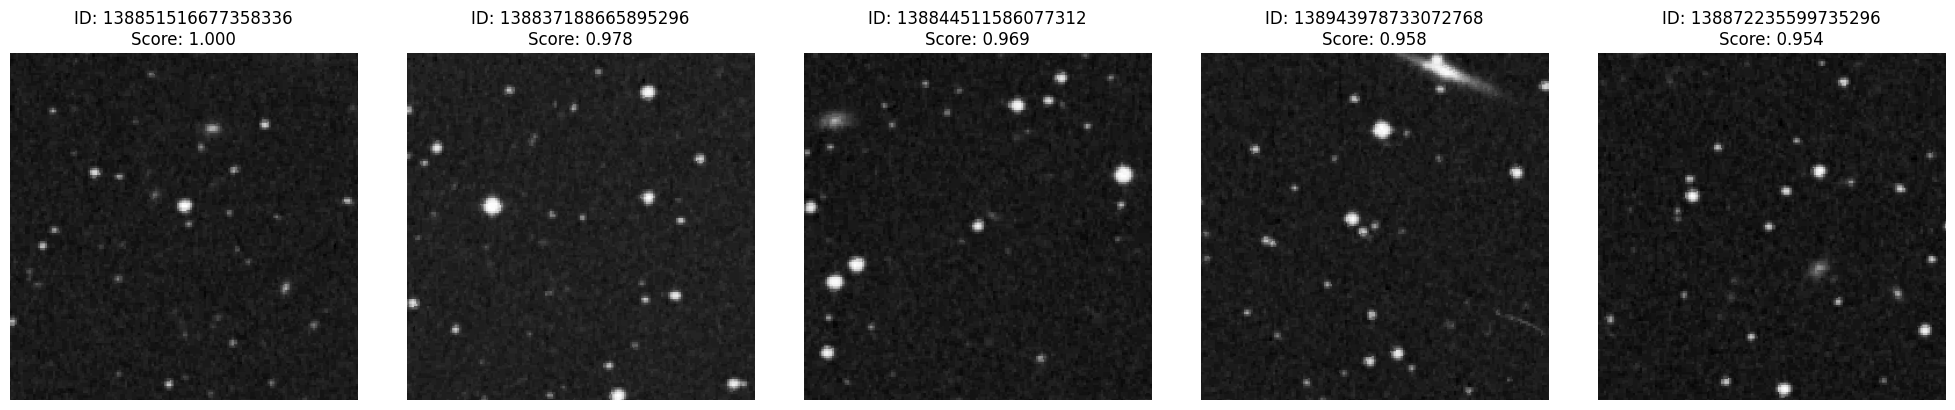

In [1]:
# Cell 1: Imports and Setup
import pandas as pd
import matplotlib.pyplot as plt
from astroquery.skyview import SkyView
from astropy.coordinates import SkyCoord
import astropy.units as u

# Cell 2: Load Validated Candidates
df_validated = pd.read_csv('../results/candidates/validated_candidates.csv')

# Filter for genuine unclassified anomalies (No SIMBAD match)
anomalies = df_validated[df_validated['known_object'] == False].copy()
print(f"Total unclassified anomalies to inspect: {len(anomalies)}")

# Cell 3: Fetch and Plot DSS Images for the Top 5 Anomalies
top_anomalies = anomalies.sort_values(by='score_All_Fused', ascending=False).head(5)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (_, row) in zip(axes, top_anomalies.iterrows()):
    coord = SkyCoord(ra=row['ra']*u.degree, dec=row['dec']*u.degree, frame='icrs')
    try:
        # Fetch DSS image cutout (Optical)
        paths = SkyView.get_images(position=coord, survey=['DSS'], radius=2*u.arcmin)
        if paths:
            img = paths[0][0].data
            ax.imshow(img, cmap='gray', origin='lower')
            ax.set_title(f"ID: {row['source_id']}\nScore: {row['score_All_Fused']:.3f}")
            ax.axis('off')
    except Exception as e:
        ax.set_title("Image Fetch Failed")
        ax.axis('off')

plt.tight_layout()
plt.show()